# STEP4. 산업별 금리 베타 추정

## 분석 질문

- 시장 전체(KOSPI) 움직임을 통제한 뒤에도 산업별 수익률이 금리 변화에 서로 다른 방향·크기로 반응하는가?
- 관련 가설: H1(산업 간 차이). 후속 가설 검정을 위한 산업별 금리 베타를 추정한다.

## 입력

- 입력 파일: `data/processed/industry_rate_panel_daily.csv`
- 구현 코드: `src/models.py` (`rate_beta`, `rate_beta_stats`, `industry_rate_betas`)
- 이전 STEP 결과: STEP2(변수 생성) · STEP3(EDA)

## 출력

- Table: `results/Baseline_industry_beta/tables/rate_beta_by_industry_hac.csv`
- Figure: `results/Baseline_industry_beta/figures/rate_beta_by_industry.png`
- Summary: `results/Baseline_industry_beta/summary.md`

In [1]:
# 설정 · 데이터 로드



import pandas as pd
import matplotlib.pyplot as plt

# 저장소 루트를 찾아 config를 불러온다 (실행 위치/편집기와 무관하게 동작).
# 저장소 루트에서 `pip install -e .` 를 한 번 실행했다면 아래 탐색은 건너뛴다.
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():          # VS Code Notebook
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):                        # IPython 커널 시작 폴더 (Jupyter/Lab/Colab)
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())           # 최후 수단

# config.py 와 requirements.txt 를 '둘 다' 가진 폴더만 저장소 루트로 인정한다.
# 마커를 하나만 보면 다른 폴더의 동명 config.py 를 잘못 집을 수 있다.
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
# 이미 sys.path에 있더라도 맨 앞으로 올린다. cwd(예: 바탕화면)가 앞에 있으면
# 같은 이름의 다른 config.py 가 먼저 잡히기 때문이다.
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))

import config

if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(
        f"의도하지 않은 config.py 가 import 되었습니다: {config.__file__}\n"
        f"저장소 루트({_root})에서 `pip install -e .` 를 실행하세요."
    )

from src import models

# 결과물 저장 경로 (후속 가설 검정용 산출물)
OUT_DIR = config.PROJECT_ROOT / "results" / "Baseline_industry_beta"
TAB_DIR = OUT_DIR / "tables"
FIG_DIR = OUT_DIR / "figures"
for _d in (TAB_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

panel = pd.read_csv(config.PROCESSED_DIR / "industry_rate_panel_daily.csv", encoding="utf-8-sig")
panel["date"] = pd.to_datetime(panel["date"])
print("패널:", panel.shape, "| 산업 수:", panel["industry"].nunique())
panel.head()

패널: (17164, 12) | 산업 수: 7


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,term_spread,d_term_spread
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN


## 회귀모형

### 목적

- 산업 수익률을 시장수익률과 금리 변화 2개 요인에 회귀하는 2지수 모형으로 산업별 금리 베타를 추정한다.

회귀식: `industry_return = α + β_rate·d_y3 + γ·kospi_return + ε`

- 각 산업에 동일한 회귀식을 적용하여 산업별 금리 베타(β_rate)를 추정한다.
- 표준오차는 HAC(Newey-West)로 보정한다. `d_y3`는 국고채 3년 금리 변화분(%p)이고, 종속·통제변수는 일별 수익률(소수)이다.

In [2]:
# 산업별 금리 베타 추정(HAC) 및 결과표 저장
beta_table = models.industry_rate_betas(panel)
beta_table.to_csv(TAB_DIR / "rate_beta_by_industry_hac.csv", index=False, encoding="utf-8-sig")
beta_table.round(5)

,industry,beta_rate,std_error,t_value,p_value,p_value_bh,ci_lower,ci_upper,n_obs,r_squared
0,건설업,0.00320,0.00834,0.38421,0.70082,0.71155,-0.01314,0.01955,2451,0.39824
1,금융업,0.01123,0.00385,2.91797,0.00352,0.00822,0.00369,0.01878,2451,0.62286
2,운수장비,0.01723,0.00581,2.96585,0.00302,0.00822,0.00584,0.02862,2451,0.47196
3,의약품,-0.02707,0.00783,-3.45610,0.00055,0.00384,-0.04242,-0.01172,2451,0.24326
4,전기전자,0.00159,0.00429,0.36977,0.71155,0.71155,-0.00682,0.01000,2451,0.71928
5,철강금속,0.01884,0.00785,2.40088,0.01636,0.02862,0.00346,0.03421,2451,0.38342
6,화학,0.00256,0.00491,0.52072,0.60256,0.71155,-0.00707,0.01219,2451,0.64364


> 이 표는 산업별 금리 베타(β_rate)와 HAC 통계를 정리하여 산업별 금리 민감도의 방향과 크기를 비교한다.

### 관찰 결과

- 유의한 음(−): 의약품 β_rate=−0.02707 (p<0.001).
- 유의한 양(+): 금융업 +0.01123·운수장비 +0.01723 (p<0.01), 철강금속 +0.01884 (p<0.05).
- 비유의: 건설업·전기전자·화학 (p>0.5).

## 산업별 금리 베타 시각화

### 목적

- 산업별 β_rate와 95% 신뢰구간을 계수 플롯으로 비교해 부호·크기 차이를 확인한다.

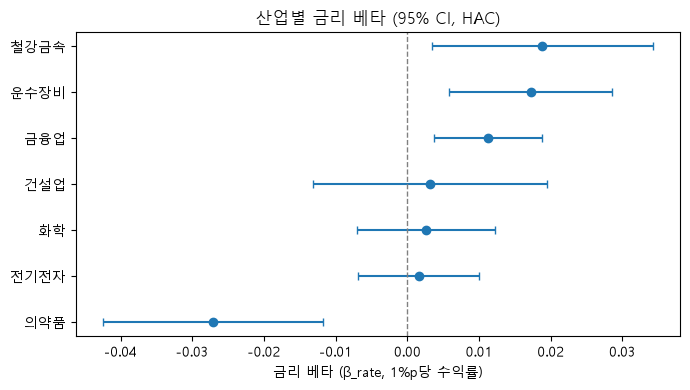

In [3]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 산업별 금리 베타 계수 플롯 (95% CI)
tbl = beta_table.sort_values("beta_rate").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(tbl["beta_rate"], range(len(tbl)),
            xerr=[tbl["beta_rate"] - tbl["ci_lower"], tbl["ci_upper"] - tbl["beta_rate"]],
            fmt="o", capsize=3)
ax.axvline(0, color="gray", lw=1, ls="--")
ax.set_yticks(range(len(tbl)))
ax.set_yticklabels(tbl["industry"])
ax.set_xlabel("금리 베타 (β_rate, 1%p당 수익률)")
ax.set_title("산업별 금리 베타 (95% CI, HAC)")
fig.tight_layout()
fig.savefig(FIG_DIR / "rate_beta_by_industry.png", dpi=150)
plt.show()

### 관찰 결과

- 가로축 β_rate, 세로축 산업(2016–2025 일별).
- 의약품만 CI가 0의 왼쪽(음), 금융·운수장비·철강금속은 CI가 0의 오른쪽(양)에 위치.
- 건설·전기전자·화학은 CI가 0을 포함(비유의).

### 해석

- 시장(KOSPI)을 통제한 뒤에도 산업별 β의 방향과 크기가 다르게 나타난다.
- 이는 금리 변화가 산업마다 다른 방향·강도로 주가에 반영될 수 있음을 시사한다.
- 추정된 β_rate는 금리 노출(민감도)이며 인과를 의미하지 않는다. 산업 간 차이의 통계적 검정은 후속 STEP에서 수행한다.

## 중간보고서용 시각화

### 목적

- 결과표(`beta_table`)를 방향·크기·유의성·설명력·다중검정 관점의 4개 그림으로 분리해 제시한다.
- 각 그림은 하나의 질문에 답하도록 구성하고, 그림 아래에 관찰과 해석을 나눠 기록한다.
- 공통 설정(입력 검증·한글 폰트·색·축 스타일)은 다음 셀에서 한 번만 정의한다.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 입력 검증
required_columns = {
    "industry", "beta_rate", "std_error", "t_value", "p_value",
    "p_value_bh", "ci_lower", "ci_upper", "n_obs", "r_squared",
}
missing_columns = required_columns.difference(beta_table.columns)
if missing_columns:
    raise ValueError("beta_table 누락 컬럼: " + ", ".join(sorted(missing_columns)))

plot_table = beta_table.copy()
numeric_columns = [
    "beta_rate", "std_error", "t_value", "p_value",
    "p_value_bh", "ci_lower", "ci_upper", "n_obs", "r_squared",
]
plot_table[numeric_columns] = plot_table[numeric_columns].apply(pd.to_numeric, errors="raise")
if plot_table[numeric_columns].isna().any().any():
    raise ValueError("시각화 입력값에 결측치가 있습니다.")

# 한글 폰트
font_candidates = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
selected_font = next((n for n in font_candidates if n in installed_fonts), "DejaVu Sans")
plt.rcParams["font.family"] = selected_font
plt.rcParams["axes.unicode_minus"] = False

# 색·축 공통 설정
REPORT_BLUE, REPORT_RED, REPORT_GRAY = "#2563EB", "#E11D48", "#94A3B8"
REPORT_DARK, GRID_COLOR = "#334155", "#E2E8F0"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def significance_group(row):
    if row["p_value_bh"] < 0.05:
        return "positive" if row["beta_rate"] > 0 else "negative"
    return "neutral"

plot_table["significance_group"] = plot_table.apply(significance_group, axis=1)
color_map = {"positive": REPORT_BLUE, "negative": REPORT_RED, "neutral": REPORT_GRAY}

def finish_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID_COLOR)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)


## 시각화 1. 산업별 금리베타 방향과 크기

### 목적

- 산업별 β_rate의 부호와 크기를 막대로 비교해 금리 반응 방향이 산업마다 갈리는지 확인한다.

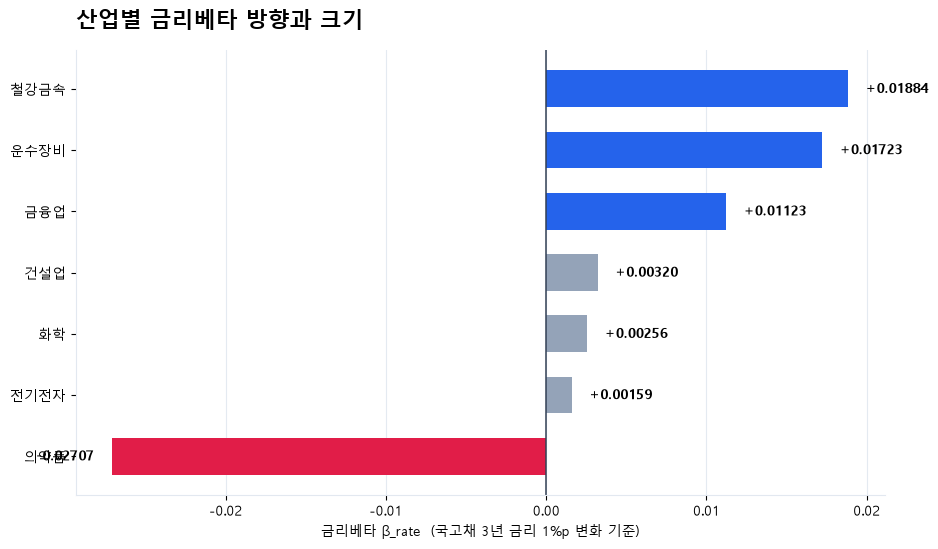

In [5]:
# 시각화 1: 산업별 금리베타 방향과 크기
beta_sorted = plot_table.sort_values("beta_rate").reset_index(drop=True)
beta_colors = beta_sorted["significance_group"].map(color_map)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
bars = ax.barh(beta_sorted["industry"], beta_sorted["beta_rate"],
               color=beta_colors, height=0.60)
ax.axvline(0, color=REPORT_DARK, linewidth=1.1)
ax.set_title("산업별 금리베타 방향과 크기", loc="left",
             fontsize=16, fontweight="bold", pad=16)
ax.set_xlabel("금리베타 β_rate  (국고채 3년 금리 1%p 변화 기준)")
finish_axis(ax)

x_span = beta_sorted["beta_rate"].max() - beta_sorted["beta_rate"].min()
label_gap = max(x_span * 0.025, 0.0008)
for bar, value in zip(bars, beta_sorted["beta_rate"]):
    y = bar.get_y() + bar.get_height() / 2
    if value >= 0:
        ax.text(value + label_gap, y, f"{value:+.5f}",
                va="center", ha="left", fontsize=10, fontweight="bold")
    else:
        ax.text(value - label_gap, y, f"{value:+.5f}",
                va="center", ha="right", fontsize=10, fontweight="bold")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_industry_rate_beta_bar.png", dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 가로축 β_rate(0 기준 오른쪽=양, 왼쪽=음), 세로축 산업(2016–2025 일별). 색: 파랑=유의 양, 빨강=유의 음, 회색=비유의.
- 의약품만 왼쪽(음, −0.02707)으로 뻗고 나머지 6개는 오른쪽(양)에 위치한다.
- 절댓값 최대는 의약품(−0.027), 다음으로 철강금속(+0.019)·운수장비(+0.017)·금융업(+0.011).

### 해석

- 같은 금리 변화가 산업에 따라 반대 방향으로 반영될 수 있음을 방향 차이로 보여준다.
- 의약품과 철강금속은 방향뿐 아니라 크기에서도 뚜렷이 대비되며, 이 차이가 후속 산업 간 차이 검정(H1)의 동기가 된다.

## 시각화 2. 산업별 금리베타와 95% 신뢰구간

### 목적

- β_rate 추정치와 95% 신뢰구간을 함께 표시해 유의성과 추정 정밀도를 확인한다.

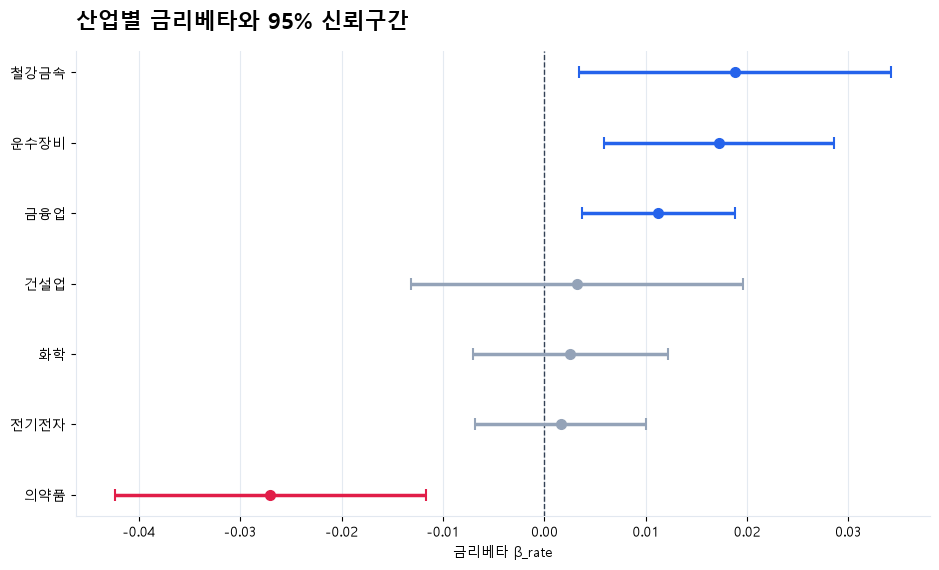

In [6]:
# 시각화 2: 산업별 금리베타와 95% 신뢰구간
coef_sorted = plot_table.sort_values("beta_rate").reset_index(drop=True)
y_positions = np.arange(len(coef_sorted))

fig, ax = plt.subplots(figsize=(9.5, 5.8))
for idx, row in coef_sorted.iterrows():
    color = color_map[row["significance_group"]]
    ax.errorbar(
        row["beta_rate"], idx,
        xerr=np.array([[row["beta_rate"] - row["ci_lower"]],
                       [row["ci_upper"] - row["beta_rate"]]]),
        fmt="o", color=color, ecolor=color, markersize=7,
        elinewidth=2.5, capsize=4, capthick=1.5, zorder=3,
    )
ax.axvline(0, color=REPORT_DARK, linewidth=1.0, linestyle="--")
ax.set_yticks(y_positions)
ax.set_yticklabels(coef_sorted["industry"])
ax.set_title("산업별 금리베타와 95% 신뢰구간", loc="left",
             fontsize=16, fontweight="bold", pad=16)
ax.set_xlabel("금리베타 β_rate")
finish_axis(ax)

fig.tight_layout()
fig.savefig(FIG_DIR / "02_industry_rate_beta_coefficient_plot.png",
            dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 점=β 추정치, 가로선=95% 신뢰구간, 세로 점선=0. 정렬 기준 β_rate.
- 금융업·철강금속·운수장비·의약품은 신뢰구간이 0을 넘지 않고, 건설업·화학·전기전자는 0을 포함한다.
- 철강금속은 유의하지만 신뢰구간 폭이 넓어 금융업보다 추정이 덜 정밀하다.

### 해석

- 신뢰구간이 0을 지나는지 여부가 곧 유의성 판정이며, 4개 산업이 유의하다.
- 신뢰구간 폭은 추정 불확실성을 함께 보여준다. 크기뿐 아니라 정밀도도 산업마다 다르다.

## 시각화 3. 산업별 모형 설명력 (R²)

### 목적

- 각 산업 회귀모형의 R²를 비교해 설명력과 금리베타 유의성의 관계를 확인한다.

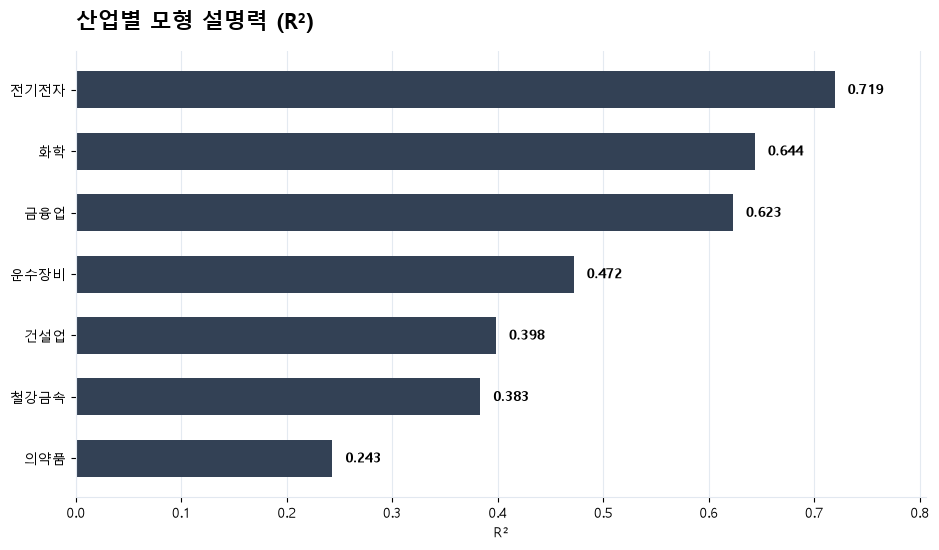

In [7]:
# 시각화 3: 산업별 모형 설명력 R²
r2_sorted = plot_table.sort_values("r_squared").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 5.6))
bars = ax.barh(r2_sorted["industry"], r2_sorted["r_squared"],
               color=REPORT_DARK, height=0.60)
ax.set_title("산업별 모형 설명력 (R²)", loc="left",
             fontsize=16, fontweight="bold", pad=16)
ax.set_xlabel("R²")
ax.set_xlim(0, max(0.80, r2_sorted["r_squared"].max() * 1.12))
finish_axis(ax)
for bar, value in zip(bars, r2_sorted["r_squared"]):
    ax.text(value + 0.012, bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}", va="center", ha="left", fontsize=10, fontweight="bold")

fig.tight_layout()
fig.savefig(FIG_DIR / "03_industry_model_r_squared.png", dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 가로축 R²(0~0.8), 세로축 산업. R²는 금리와 KOSPI 통제변수를 포함한 모형 전체의 설명력이다.
- 전기전자(0.719)·화학(0.644)이 최고, 의약품(0.243)이 최저.
- 전기전자·화학은 R²가 높지만 금리베타는 비유의하고, 의약품은 R²가 낮아도 금리베타는 최대·유의하다.

### 해석

- 높은 R²가 곧 강한 금리효과를 의미하지는 않는다.
- R²가 높은 산업은 움직임 대부분이 시장 전체 흐름으로 설명되고 금리 고유 효과는 약하다.

## 시각화 4. 원 p-value와 BH 보정 p-value 비교

### 목적

- 7개 산업 동시검정을 반영한 BH 보정 후에도 유의성이 유지되는지 확인한다.

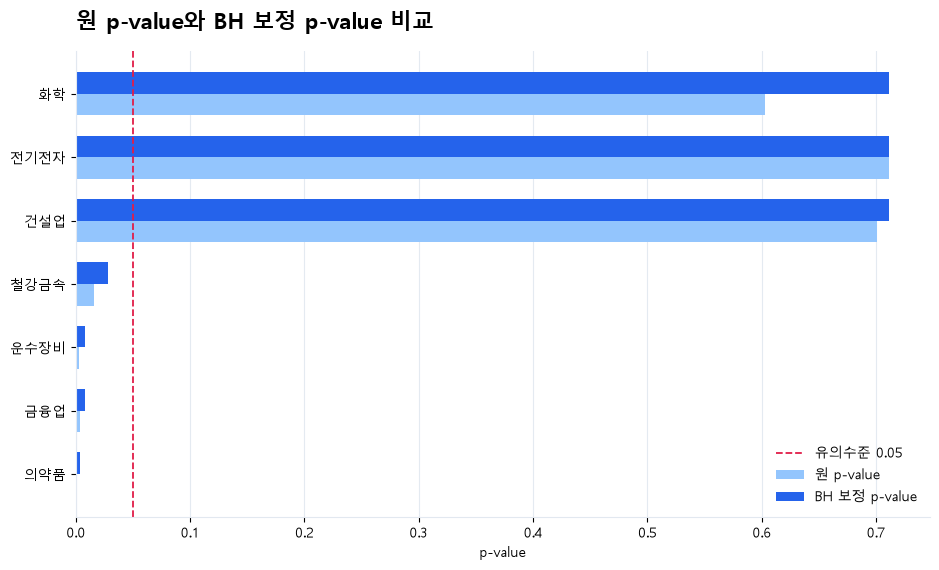

In [8]:
# 시각화 4: 원 p-value와 BH 보정 p-value 비교
p_sorted = plot_table.sort_values("p_value_bh").reset_index(drop=True)
y_positions = np.arange(len(p_sorted))
bar_height = 0.34

fig, ax = plt.subplots(figsize=(9.5, 5.8))
ax.barh(y_positions - bar_height / 2, p_sorted["p_value"],
        height=bar_height, color="#93C5FD", label="원 p-value")
ax.barh(y_positions + bar_height / 2, p_sorted["p_value_bh"],
        height=bar_height, color=REPORT_BLUE, label="BH 보정 p-value")
ax.axvline(0.05, color=REPORT_RED, linewidth=1.3, linestyle="--", label="유의수준 0.05")
ax.set_yticks(y_positions)
ax.set_yticklabels(p_sorted["industry"])
ax.set_title("원 p-value와 BH 보정 p-value 비교", loc="left",
             fontsize=16, fontweight="bold", pad=16)
ax.set_xlabel("p-value")
ax.legend(frameon=False, loc="lower right")
finish_axis(ax)

fig.tight_layout()
fig.savefig(FIG_DIR / "04_raw_vs_bh_pvalue.png", dpi=200, bbox_inches="tight")
plt.show()


### 관찰 결과

- 연한 막대=원 p-value, 진한 막대=BH 보정 p-value, 빨간 점선=유의수준 0.05. 정렬 기준 BH p-value.
- BH 보정은 모든 산업의 p-value를 오른쪽(값 증가)으로 민다.
- 그럼에도 의약품·운수장비·금융업·철강금속은 0.05 선 왼쪽에 남는다.

### 해석

- 7개 산업 동시검정의 위양성을 통제한 뒤에도 4개 산업의 유의성이 유지된다.
- 핵심 결과가 다중검정 보정 후에도 우연으로 뒤집히지 않음을 뜻한다.

## 결과표 값 일치 검증

> 이 표는 시각화에 사용한 값이 HTML 보고서 결과표와 동일한지 확인한다. β_rate와 1%p당 수익률(%) 환산값을 함께 보여 단위 해석을 돕는다.

In [9]:
# HTML 결과표와 값 일치 여부 확인
html_check = plot_table[
    ["industry", "beta_rate", "std_error", "t_value", "p_value",
     "p_value_bh", "ci_lower", "ci_upper", "r_squared", "n_obs"]
].copy()
html_check["return_per_1pp_pct"] = html_check["beta_rate"] * 100
html_check = html_check[
    ["industry", "beta_rate", "return_per_1pp_pct", "std_error", "t_value",
     "p_value", "p_value_bh", "ci_lower", "ci_upper", "r_squared", "n_obs"]
]
display(html_check.round(5))

# 개인 PC 절대경로를 출력에 남기지 않는다 (config._rel: 저장소 루트 기준 상대경로).
print("\n저장 완료:")
for file_name in [
    "01_industry_rate_beta_bar.png",
    "02_industry_rate_beta_coefficient_plot.png",
    "03_industry_model_r_squared.png",
    "04_raw_vs_bh_pvalue.png",
]:
    print(" -", config._rel(FIG_DIR / file_name))


,industry,beta_rate,return_per_1pp_pct,std_error,t_value,p_value,p_value_bh,ci_lower,ci_upper,r_squared,n_obs
0,건설업,0.00320,0.32047,0.00834,0.38421,0.70082,0.71155,-0.01314,0.01955,0.39824,2451
1,금융업,0.01123,1.12336,0.00385,2.91797,0.00352,0.00822,0.00369,0.01878,0.62286,2451
2,운수장비,0.01723,1.72294,0.00581,2.96585,0.00302,0.00822,0.00584,0.02862,0.47196,2451
3,의약품,-0.02707,-2.70663,0.00783,-3.45610,0.00055,0.00384,-0.04242,-0.01172,0.24326,2451
4,전기전자,0.00159,0.15870,0.00429,0.36977,0.71155,0.71155,-0.00682,0.01000,0.71928,2451
5,철강금속,0.01884,1.88355,0.00785,2.40088,0.01636,0.02862,0.00346,0.03421,0.38342,2451
6,화학,0.00256,0.25583,0.00491,0.52072,0.60256,0.71155,-0.00707,0.01219,0.64364,2451



저장 완료:
 - results\Baseline_industry_beta\figures\01_industry_rate_beta_bar.png
 - results\Baseline_industry_beta\figures\02_industry_rate_beta_coefficient_plot.png
 - results\Baseline_industry_beta\figures\03_industry_model_r_squared.png
 - results\Baseline_industry_beta\figures\04_raw_vs_bh_pvalue.png


## 구현 검증

- 아래 셀에서 결과표가 설계 계약(행·산업 수·컬럼·자료형·결측/Inf·p·R²·표준오차·신뢰구간·관측치·재현성·HAC 적용·함수 일관성)을 만족하는지 `assert`로 자동 검증한다. 실패 시 즉시 오류가 발생한다.

In [10]:
# 구현 검증: 결과표(beta_table)가 설계 계약을 만족하는지 assert로 자동 검증 (실패 시 즉시 중단)
import numpy as np
import statsmodels.api as sm

EXPECTED_INDUSTRIES = {"건설업", "금융업", "화학", "전기전자", "철강금속", "의약품", "운수장비"}
REQUIRED_COLS = ["industry", "beta_rate", "std_error", "t_value", "p_value", "p_value_bh",
                 "ci_lower", "ci_upper", "n_obs", "r_squared"]
NUM_COLS = ["beta_rate", "std_error", "t_value", "p_value", "p_value_bh",
            "ci_lower", "ci_upper", "r_squared"]
KEY_COLS = ["industry_return", "kospi_return", "d_y3"]

# 행·산업·필수 컬럼 존재(순서·추가 컬럼 무관)
assert len(beta_table) == 7
assert beta_table["industry"].nunique() == 7
assert set(beta_table["industry"]) == EXPECTED_INDUSTRIES
assert not (set(REQUIRED_COLS) - set(beta_table.columns)), "필수 컬럼 누락"

# 자료형(n_obs 정수, 통계량 실수)
assert str(beta_table["n_obs"].dtype).startswith("int")
assert all(np.issubdtype(beta_table[c].dtype, np.floating) for c in NUM_COLS)

# 결측치·Inf 없음
assert not beta_table[REQUIRED_COLS].isna().any().any()
assert np.isfinite(beta_table[NUM_COLS].to_numpy()).all()

# 값 범위(p·p_bh·R² ∈ [0,1], 표준오차 > 0)
assert beta_table["p_value"].between(0, 1).all()
assert beta_table["p_value_bh"].between(0, 1).all()
assert beta_table["r_squared"].between(0, 1).all()
assert (beta_table["std_error"] > 0).all()

# 다중검정 보정 방향(BH 보정 p ≥ 원 p)
assert (beta_table["p_value_bh"] >= beta_table["p_value"] - 1e-9).all()

# 신뢰구간 일관성(하한 < 상한, 하한 ≤ beta ≤ 상한)
assert (beta_table["ci_lower"] < beta_table["ci_upper"]).all()
assert ((beta_table["ci_lower"] <= beta_table["beta_rate"]) &
        (beta_table["beta_rate"] <= beta_table["ci_upper"])).all()

# t_value = beta_rate / std_error
assert np.allclose(beta_table["t_value"], beta_table["beta_rate"] / beta_table["std_error"], rtol=1e-6)

# 관측치 수 = 산업별 dropna 관측수
exp_n = panel.dropna(subset=KEY_COLS).groupby("industry").size()
for _, row in beta_table.iterrows():
    assert row["n_obs"] > 0
    assert row["n_obs"] == exp_n[row["industry"]], f"{row['industry']} 관측치 수 불일치"

# 재현성(동일 입력 재실행 결과 동일)
pd.testing.assert_frame_equal(beta_table, models.industry_rate_betas(panel))

# HAC 실제 적용(동일 회귀의 OLS 표준오차와 다르되 계수는 동일)
g = panel[panel["industry"] == "금융업"].dropna(subset=KEY_COLS)
X = sm.add_constant(g[["kospi_return", "d_y3"]])
hac = sm.OLS(g["industry_return"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
ols = sm.OLS(g["industry_return"], X).fit()
assert abs(hac.params["d_y3"] - ols.params["d_y3"]) < 1e-12
assert abs(hac.bse["d_y3"] - ols.bse["d_y3"]) > 1e-9

# 핵심 함수 일관성(rate_beta의 베타 == 결과표의 해당 산업 베타)
b, _se, _p = models.rate_beta(g["industry_return"], g["kospi_return"], g["d_y3"])
assert np.isclose(b, beta_table.loc[beta_table["industry"] == "금융업", "beta_rate"].iloc[0])

print("모든 구현 검증 통과 — 7개 산업, 12개 항목")

모든 구현 검증 통과 — 7개 산업, 12개 항목


### 검증 결과 및 해석

**검증한 항목**

- 구조: 7개 산업·행 수, 필수 컬럼(BH 보정 `p_value_bh` 포함), 자료형, 결측·Inf 없음.
- 값·통계 일관성: p·p_bh·R² 범위, 표준오차 > 0, 신뢰구간(하한 < 상한·beta 포함), t = beta/SE, BH 보정 p ≥ 원 p.
- 관측치: 산업별 표본 수가 dropna 관측수와 일치.
- 재현성·구현: 재실행 결과 동일, HAC 실제 적용(OLS와 표준오차 상이·계수 동일), `rate_beta`와 결과표 일치.

**해석**

- 결과표가 설계 계약을 모두 만족하므로 후속 H1·H2 검정이 이 표를 그대로 신뢰·재사용할 수 있다.
- HAC가 실제 적용되어 유의성이 과장되지 않았고, BH 보정으로 다중검정 위양성 위험을 통제한다.
- 재현성이 보장되어 동일 데이터에서 결과가 항상 같다.
- 검증 셀이 통과 메시지를 출력하면 모든 항목이 성립한 것이며, 하나라도 위배되면 즉시 `AssertionError`로 중단된다.

## STEP4 요약

### Takeaway

- 산업별 2지수 모형(HAC)으로 7개 산업의 금리 베타를 추정하였다.
- 의약품(−0.02707)만 유의한 음, 금융·운수장비·철강금속은 유의한 양, 나머지 3개는 비유의.
- 추정 결과는 후속 가설 검정의 입력으로 활용된다.
- 결과표·계수 플롯을 `results/Baseline_industry_beta/`에 저장하였다.
- 상세: `results/Baseline_industry_beta/summary.md`